# Traffic Collision Data Analysis

# Objective

In this case study, you will be working on California Traffic Collision Data Analysis using Apache Spark, a powerful distributed computing framework designed for big data processing. This assignment aims to provide hands-on experience in analyzing large-scale traffic collision datasets using PySpark and AWS services. You will apply data analytics techniques to clean, transform, and explore crash data, drawing meaningful insights to support traffic safety and urban planning. Beyond understanding how big data tools optimize performance on a single machine and across clusters, you will develop a structured approach to analyzing crash trends, identifying high-risk locations, and evaluating contributing factors to traffic incidents. Additionally, you will utilize AWS S3 to store the processed data efficiently after the ETL process, enabling scalable storage and easy retrieval for further analysis.


# Business Value:

Traffic collisions pose significant risks to public safety, requiring continuous monitoring and analysis to enhance road safety measures. Government agencies, city planners, and policymakers must leverage data-driven insights to improve infrastructure, optimize traffic management, and implement preventive measures.

In this assignment, you will analyze California traffic collision data to uncover patterns related to accident severity, location-based risks, and key contributing factors. With Apache Spark's ability to handle large datasets efficiently and AWS S3's scalable storage, transportation authorities can process vast amounts of crash data in real time, enabling faster and more informed decision-making.

As an analyst examining traffic safety trends, your task is to analyze historical crash data to derive actionable insights that can drive policy improvements and safety interventions. Your analysis will help identify high-risk areas, categorize accidents by severity and contributing factors, and store the processed data in an AWS S3 bucket for scalable and long-term storage.

By leveraging big data analytics and cloud-based storage, urban planners and traffic authorities can enhance road safety strategies, reduce accident rates, and improve public transportation planning.


# Dataset Overview

The dataset used in this analysis consists of California traffic collision data obtained from the Statewide Integrated Traffic Records System (SWITRS). It includes detailed records of traffic incidents across California, covering various attributes such as location, severity, involved parties, and contributing factors. The dataset has been preprocessed and transformed using PySpark to facilitate large-scale analysis. By leveraging Apache Spark, we ensure efficient data handling, enabling deeper insights into traffic patterns, accident trends, and potential safety improvements.

The dataset is a .sqlite file contains detailed information about traffic collisions across California and is structured into four primary tables:
- `collisions` table contains information about the collision, where it happened, what vehicles were involved.

- `parties` table contains information about the groups people involved in the collision including age, sex, and sobriety.

- `victims` table contains information about the injuries of specific people involved in the collision.

- `locations` table contains information about the geographical location and details of road intersections.

# Assignment Tasks

<ol>
    <li>
        <strong>Data Preparation</strong></br>
        The dataset consists of structured tables containing traffic collision data. Before conducting any analysis, it is essential to ensure that the data is properly formatted and structured for efficient processing.</br>
        Check for data consistency and ensure all columns are correctly formatted.</br>
        Apply sampling techniques if needed to extract a representative subset for analysis.</br>
        Structure and prepare the data for further processing and analysis.</br>
    </br>
    <li>
        <strong>Data Cleaning</strong></br>
            2.1 <strong>Fixing Columns:</strong> Ensure all columns are properly named and formatted.</br>
            2.2 <strong>Handling Missing Values:</strong> Decide on an approach to handle missing data (e.g., imputation or removal). Mention the approach in your report.</br>
            2.3 <strong>Handling Outliers:</strong> Identify outliers in the dataset and explain why they are considered outliers. It is not necessary to remove them for this task, but mention your approach for handling them.</br>
    </br>
    <li>
        <strong>Exploratory Data Analysis</strong></br>
        Finding Patterns and analyze the dataset and find patterns based on the following points:
                <ul>
                3.1 Classify variables into categorical and numerical types.</br>
                3.2 Analyze the distribution of collision severity.</br>
                3.3 Examine weather conditions during collisions.</br>
                3.4 Analyze the distribution of victim ages.</br>
                3.5 Study the relationship between collision severity and the number of victims.</br>
                3.6 Analyze the correlation between weather conditions and collision severity.</br>
                3.7 Visualize the impact of lighting conditions on collision severity.</br>
                3.8 Extract and analyze weekday-wise collision trends.</br>
                3.9 Assess the number of collisions occurring on different days of the week.</br>
                3.10 Study spatial distribution of collisions by county.</br>
                3.11 Generate a scatter plot to analyze collision locations geographically.</br>
                3.12 Extract and analyze collision trends over time, including yearly, monthly, and hourly trends.</br>
</ul>
</br>
<li>
<strong>ETL Querying</strong><br>
Write PySpark SQL queries for the following:</br>
<ol>
    4.1. Identify the top 5 counties with the highest number of collisions.</br>
    4.2. Identify the month with the highest number of collisions.</br>
    4.3. Determine the most common weather condition during collisions.</br>
    4.4. Calculate the percentage of collisions that resulted in fatalities.</br>
    4.5. Find the most dangerous time of day for collisions.</br>
    4.6. Identify the top 5 road surface conditions with the highest collision frequency.</br>
    4.7. Analyze lighting conditions that contribute to the highest number of collisions.</br>
</ol>
</br>
<li>
<strong>Conclusion</strong></br>
Provide final insights and recommendations based on the analysis:
    <ul>
        5.1 Recommendations to improve road safety by identifying high-risk locations and peak accident times for infrastructure improvements.</br>
        5.2 Suggestions to optimize traffic management by analyzing trends in collision severity, weather conditions, and lighting to improve road design and traffic signal timing.</br>
        5.3 Propose data-driven policy changes to enhance pedestrian and cyclist safety based on collision trends involving vulnerable road users.</br>
        5.4 Identify potential high-risk zones for proactive intervention by examining geographic collision density and historical accident data.</br>
        5.5 Assess the impact of environmental factors such as weather, road surface conditions, and lighting on accident frequency and severity.</br>
        5.6 Develop predictive models to anticipate collision hotspots and support proactive safety measures.</br>
        </ul>
        Conclude the analysis by summarizing key findings and business implications.</br>
        Explain the results of univariate, segmented univariate, and bivariate analyses in real-world traffic safety and policy terms.</br>
        Include visualizations and summarize the most important results in the report. Insights should explain why each variable is important and how they can influence traffic safety policies and urban planning.</br>
        </ul>
        </br>
    <li>
    <strong>Visualization Integration [Optional]</strong>
    <p>Enhance the project by incorporating a visualization component that connects the processed data stored in an S3 bucket to a business intelligence tool such as Tableau or Power BI. This involves setting up the connection between the S3 bucket and the chosen visualization tool, importing the processed dataset for analysis and visualization, creating interactive dashboards to explore key trends and insights and ensuring data updates are reflected dynamically in the visualization tool.<br>
</br>
</ol>

In [ ]:
#from google.colab import drive
#drive.mount('/content/drive')

Install Required Libraries

In [1]:
## Install the required libraries
# !pip install --quiet pyspark==3.5.4 pandas==2.2.2

In [20]:
# Import the necessary libraries
import sqlite3
import pandas as pd
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.functions import col, sum, to_date

#**1. Data Preparation** <font color = red>[5 marks]</font> <br>

The dataset consists of structured tables containing traffic collision data.

Before conducting any analysis, it is essential to ensure that the data is properly formatted and structured for efficient processing.

Check for data consistency and ensure all columns are correctly formatted.

In [21]:
spark = SparkSession.builder.appName("CollisionData").getOrCreate()

# Write code to load the data and check the schema
collisions_df = spark.read.csv("sample_collisions.csv", header=True, inferSchema=True)
parties_df = spark.read.csv("sample_parties.csv", header=True, inferSchema=True)
victims_df = spark.read.csv("sample_victims.csv", header=True, inferSchema=True)
case_ids_df = spark.read.csv("sample_case_ids.csv", header=True, inferSchema=True)

#**2. Data Cleaning** <font color = red>[20 marks]</font> <br>


In [22]:
#Display Schema & Sample Data
collisions_df.printSchema()
collisions_df.show(5)

root
 |-- case_id: double (nullable = true)
 |-- jurisdiction: double (nullable = true)
 |-- officer_id: string (nullable = true)
 |-- reporting_district: string (nullable = true)
 |-- chp_shift: string (nullable = true)
 |-- population: string (nullable = true)
 |-- county_city_location: integer (nullable = true)
 |-- county_location: string (nullable = true)
 |-- special_condition: double (nullable = true)
 |-- beat_type: string (nullable = true)
 |-- chp_beat_type: string (nullable = true)
 |-- chp_beat_class: string (nullable = true)
 |-- beat_number: string (nullable = true)
 |-- primary_road: string (nullable = true)
 |-- secondary_road: string (nullable = true)
 |-- distance: double (nullable = true)
 |-- direction: string (nullable = true)
 |-- intersection: double (nullable = true)
 |-- weather_1: string (nullable = true)
 |-- state_highway_indicator: double (nullable = true)
 |-- caltrans_county: string (nullable = true)
 |-- caltrans_district: double (nullable = true)
 |-- s

In [4]:
parties_df.printSchema()
parties_df.show(5)

root
 |-- id: integer (nullable = true)
 |-- case_id: double (nullable = true)
 |-- party_number: integer (nullable = true)
 |-- party_type: string (nullable = true)
 |-- at_fault: integer (nullable = true)
 |-- party_sex: string (nullable = true)
 |-- party_age: double (nullable = true)
 |-- party_sobriety: string (nullable = true)
 |-- direction_of_travel: string (nullable = true)
 |-- party_safety_equipment_1: string (nullable = true)
 |-- party_safety_equipment_2: string (nullable = true)
 |-- financial_responsibility: string (nullable = true)
 |-- cellphone_in_use: double (nullable = true)
 |-- cellphone_use_type: string (nullable = true)
 |-- other_associate_factor_1: string (nullable = true)
 |-- party_number_killed: integer (nullable = true)
 |-- party_number_injured: integer (nullable = true)
 |-- movement_preceding_collision: string (nullable = true)
 |-- vehicle_year: double (nullable = true)
 |-- vehicle_make: string (nullable = true)
 |-- statewide_vehicle_type: string (nu

In [23]:
victims_df.printSchema()
victims_df.show(5)

root
 |-- id: integer (nullable = true)
 |-- case_id: double (nullable = true)
 |-- party_number: integer (nullable = true)
 |-- victim_role: string (nullable = true)
 |-- victim_sex: string (nullable = true)
 |-- victim_age: double (nullable = true)
 |-- victim_degree_of_injury: string (nullable = true)
 |-- victim_seating_position: string (nullable = true)
 |-- victim_safety_equipment_1: string (nullable = true)
 |-- victim_safety_equipment_2: string (nullable = true)
 |-- victim_ejected: string (nullable = true)

+-------+-----------+------------+-----------+----------+----------+-----------------------+-----------------------+-------------------------+-------------------------+--------------+
|     id|    case_id|party_number|victim_role|victim_sex|victim_age|victim_degree_of_injury|victim_seating_position|victim_safety_equipment_1|victim_safety_equipment_2|victim_ejected|
+-------+-----------+------------+-----------+----------+----------+-----------------------+------------------

In [24]:
case_ids_df.printSchema()
case_ids_df.show(5)

root
 |-- case_id: double (nullable = true)
 |-- db_year: integer (nullable = true)

+-----------+-------+
|    case_id|db_year|
+-----------+-------+
|9.0017156E7|   2021|
|  4078685.0|   2021|
|9.0588783E7|   2021|
|  3351919.0|   2018|
|   632208.0|   2018|
+-----------+-------+
only showing top 5 rows



##**2.1 Missing Values** <font color = red>[10 marks]</font> <br>


In [25]:
collisions_df_missing_values_dict = collisions_df.select([
    F.avg(F.col(c).isNull().cast("double")).alias(c)
    for c in collisions_df.columns
]).first().asDict()

print(collisions_df_missing_values_dict)

{'case_id': 0.0, 'jurisdiction': 0.0012374557994252991, 'officer_id': 0.002419343635491258, 'reporting_district': 0.590573108739024, 'chp_shift': 0.0, 'population': 0.0001763214221979053, 'county_city_location': 0.0, 'county_location': 0.0, 'special_condition': 0.05527943739574328, 'beat_type': 0.0, 'chp_beat_type': 0.0, 'chp_beat_class': 0.0002928004223165215, 'beat_number': 0.0863226938493745, 'primary_road': 1.0686146799873048e-05, 'secondary_road': 2.1372293599746096e-06, 'distance': 0.0, 'direction': 0.2486270972898863, 'intersection': 0.0101347416249996, 'weather_1': 0.004943411509621272, 'state_highway_indicator': 0.00033981946823596296, 'caltrans_county': 0.7288753578523409, 'caltrans_district': 0.6932402641188044, 'state_route': 0.6932402641188044, 'postmile': 0.6932402641188044, 'location_type': 0.7288753578523409, 'side_of_highway': 0.728877495081701, 'tow_away': 0.006575186125961887, 'collision_severity': 0.0, 'killed_victims': 0.00021372293599746097, 'injured_victims': 0.0

In [26]:
victims_df_missing_values_dict = victims_df.select([
    F.avg(F.col(c).isNull().cast("double")).alias(c)
    for c in victims_df.columns
]).first().asDict()

print(victims_df_missing_values_dict)

{'id': 0.0, 'case_id': 0.0, 'party_number': 0.0, 'victim_role': 1.0374165009393807e-06, 'victim_sex': 0.02494053009908365, 'victim_age': 0.03334775342269639, 'victim_degree_of_injury': 0.0, 'victim_seating_position': 0.0019845777662970353, 'victim_safety_equipment_1': 0.0572809520993679, 'victim_safety_equipment_2': 0.3218273469214147, 'victim_ejected': 0.004431843292013034}


In [27]:
parties_df_missing_values_dict = parties_df.select([
    F.avg(F.col(c).isNull().cast("double")).alias(c)
    for c in parties_df.columns
]).first().asDict()

print(parties_df_missing_values_dict)

{'id': 0.0, 'case_id': 0.0, 'party_number': 0.0, 'party_type': 0.002354148577574686, 'at_fault': 0.0, 'party_sex': 0.13351905842627176, 'party_age': 0.15575571918837314, 'party_sobriety': 0.029815465818780373, 'direction_of_travel': 0.028055344720734773, 'party_safety_equipment_1': 0.16866470228724684, 'party_safety_equipment_2': 0.37472528237730973, 'financial_responsibility': 0.08174600156300467, 'cellphone_in_use': 0.3043504344328109, 'cellphone_use_type': 0.23153894897309307, 'other_associate_factor_1': 0.060257633306676196, 'party_number_killed': 0.0, 'party_number_injured': 0.0, 'movement_preceding_collision': 0.017823502598133714, 'vehicle_year': 0.09512956387455897, 'vehicle_make': 0.10448080980568498, 'statewide_vehicle_type': 0.11285611518883806, 'chp_vehicle_type_towing': 0.21486868457462222, 'chp_vehicle_type_towed': 0.4871898429335637, 'party_race': 0.2339921914043313}


In [28]:
case_ids_df_missing_values_dict = case_ids_df.select([
    F.avg(F.col(c).isNull().cast("double")).alias(c)
    for c in case_ids_df.columns
]).first().asDict()

print(case_ids_df_missing_values_dict)

{'case_id': 0.0, 'db_year': 0.0}


In [29]:
#Drop Sparse Columns
# Identify columns with more than 80% null values
sparse_columns = [
    column
    for column, null_rate in collisions_df_missing_values_dict.items()
    if null_rate is not None and null_rate > 0.80
]

# Drop those columns
collisions_df = collisions_df.drop(*sparse_columns)

print("Dropped columns:", sparse_columns)
print("Remaining columns:", len(collisions_df.columns))

# Identify columns with more than 80% null values
sparse_columns = [
    column
    for column, null_rate in victims_df_missing_values_dict.items()
    if null_rate is not None and null_rate > 0.80
]

# Drop those columns
victims_df = victims_df.drop(*sparse_columns)

print("Dropped columns:", sparse_columns)
print("Remaining columns:", len(victims_df.columns))

# Identify columns with more than 80% null values
sparse_columns = [
    column
    for column, null_rate in case_ids_df_missing_values_dict.items()
    if null_rate is not None and null_rate > 0.80
]

# Drop those columns
case_ids_df = case_ids_df.drop(*sparse_columns)

print("Dropped columns:", sparse_columns)
print("Remaining columns:", len(case_ids_df.columns))


# Identify columns with more than 80% null values
sparse_columns = [
    column
    for column, null_rate in parties_df_missing_values_dict.items()
    if null_rate is not None and null_rate > 0.80
]

# Drop those columns
parties_df = parties_df.drop(*sparse_columns)

print("Dropped columns:", sparse_columns)
print("Remaining columns:", len(parties_df.columns))


Dropped columns: []
Remaining columns: 65
Dropped columns: []
Remaining columns: 11
Dropped columns: []
Remaining columns: 2
Dropped columns: []
Remaining columns: 24


In [30]:
#Convert Data Types

# Assumes these columns contain whole-number values
collisions_df = collisions_df.withColumn(
    "case_id", F.col("case_id").cast("long")
)

count_columns = [
    "killed_victims",
    "injured_victims",
    "party_count",
    "motorcyclist_injured_count"
]

for column in count_columns:
    collisions_df = collisions_df.withColumn(
        column, F.col(column).cast("int")
    )


victims_df = (
    victims_df
    .withColumn("case_id", F.col("case_id").cast("long"))
    .withColumn("victim_age", F.col("victim_age").cast("int"))
)

parties_df = (
    parties_df
    .withColumn("case_id", F.col("case_id").cast("long"))
    .withColumn("party_age", F.col("party_age").cast("int"))
    .withColumn("vehicle_year", F.col("vehicle_year").cast("int"))
    .withColumn("cellphone_in_use", F.col("cellphone_in_use").cast("int"))
)

case_ids_df = case_ids_df.withColumn(
    "case_id", F.col("case_id").cast("long")
)

case_ids_df.printSchema()

root
 |-- case_id: long (nullable = true)
 |-- db_year: integer (nullable = true)



In [31]:
#Handle Missing Values
#1. Drop rows missing the keys needed for joins
collisions_df = collisions_df.dropna(subset = ["case_id"])

victims_df = victims_df.dropna(subset = ["id", "case_id", "party_number"])

parties_df = parties_df.dropna(
    subset=["id", "case_id", "party_number"]
)

case_ids_df = case_ids_df.dropna(subset=["case_id"])

#2. Fill missing string values with "Unknown"
def fill_missing_strings(df):
    string_columns = [
        field.name for field in df.schema.fields if field.dataType.simpleString() == "string"
    ]

    for col in string_columns:
        df = df.fillna({col: "Unknown"})
    return df


collisions_df = fill_missing_strings(collisions_df)
victims_df = fill_missing_strings(victims_df)
parties_df = fill_missing_strings(parties_df)
case_ids_df = fill_missing_strings(case_ids_df)

# 3. Leave remaining numeric, date, and timestamp nulls unchanged.

##**2.2 Fixing Columns** <font color = red>[5 marks]</font> <br>


In [32]:
#Remove Duplicates - Ensuring unique records based on key identifiers
collisions_df = collisions_df.dropDuplicates(["case_id"])
victims_df = victims_df.dropDuplicates(["id"])
parties_df = parties_df.dropDuplicates(["id"])
case_ids_df = case_ids_df.dropDuplicates(["case_id"])

In [33]:
#Detect Outliers using IQR
def remove_outliers(df, columns):
    for column in columns:
        quantiles = df.approxQuantile(column, [0.25, 0.75], 0.01)

        # Skip columns with no usable values
        if len(quantiles) != 2:
            continue

        q1, q3 = quantiles
        iqr = q3 - q1

        # With zero IQR, the rule can flag ordinary non-zero counts
        if iqr == 0:
            print(f"Skipped {column}: IQR is zero")
            continue

        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        df = df.filter(
            F.col(column).isNull() | F.col(column).between(lower, upper)
        )

    return df


# List of numerical columns to check for outliers
collisions_outlier_columns = [
    "distance",
    "killed_victims",
    "injured_victims",
    "party_count",
    "severe_injury_count",
    "other_visible_injury_count",
    "complaint_of_pain_injury_count",
    "pedestrian_killed_count",
    "pedestrian_injured_count",
    "bicyclist_killed_count",
    "bicyclist_injured_count",
    "motorcyclist_killed_count",
    "motorcyclist_injured_count"
]

victims_outlier_columns = ["victim_age"]

parties_outlier_columns = [
    "party_age",
    "party_number_killed",
    "party_number_injured"
]

##**2.3 Outlier Analysis** <font color = red>[5 marks]</font> <br>


In [34]:
#Remove Outliers
collisions_df = remove_outliers(collisions_df, collisions_outlier_columns)
victims_df = remove_outliers(victims_df, victims_outlier_columns)
parties_df = remove_outliers(parties_df, parties_outlier_columns)

Skipped killed_victims: IQR is zero


Skipped party_count: IQR is zero


Skipped severe_injury_count: IQR is zero


Skipped other_visible_injury_count: IQR is zero


Skipped pedestrian_killed_count: IQR is zero


Skipped pedestrian_injured_count: IQR is zero


... (2 outputs left out)

Skipped motorcyclist_killed_count: IQR is zero


Skipped motorcyclist_injured_count: IQR is zero


Skipped party_number_killed: IQR is zero


Skipped party_number_injured: IQR is zero


#**3. Exploratory Data Analysis** <font color = red>[65 marks]</font> <br>


##**3.1.1. Data Preparation** <font color = red>[5 marks]</font> <br>

Q: Classify variables into categorical and numerical.

In [35]:
from pyspark.ml.feature import StringIndexer

# Encode Categorical Variables
collisions_categorical_columns = [
    "collision_severity",
    "weather_1",
    "lighting",
    "road_surface",
    "road_condition_1",
    "type_of_collision",
    "county_location"
]

parties_categorical_columns = [
    "party_type",
    "party_sex",
    "party_sobriety"
]

victims_categorical_columns = [
    "victim_role",
    "victim_sex",
    "victim_degree_of_injury"
]

# String Indexing for Categorical Columns
def encode_categories(df, columns):
    # Remove previously generated indexes if this cell is rerun
    df = df.drop(*[f"{column}_index" for column in columns])

    indexer = StringIndexer(
        inputCols=columns,
        outputCols=[f"{column}_index" for column in columns],
        handleInvalid="keep",
        stringOrderType="alphabetAsc"
    )

    model = indexer.fit(df)
    return model.transform(df), model


collisions_df, collisions_indexer_model = encode_categories(
    collisions_df, collisions_categorical_columns
)

parties_df, parties_indexer_model = encode_categories(
    parties_df, parties_categorical_columns
)

victims_df, victims_indexer_model = encode_categories(
    victims_df, victims_categorical_columns
)

# Display original categories and their encoded values
collisions_df.select(
    "collision_severity",
    "collision_severity_index",
    "weather_1",
    "weather_1_index"
).show(5, truncate=False)

+--------------------+------------------------+---------+---------------+
|collision_severity  |collision_severity_index|weather_1|weather_1_index|
+--------------------+------------------------+---------+---------------+
|property damage only|2.0                     |clear    |1.0            |
|property damage only|2.0                     |clear    |1.0            |
|property damage only|2.0                     |clear    |1.0            |
|property damage only|2.0                     |clear    |1.0            |
|pain                |1.0                     |clear    |1.0            |
+--------------------+------------------------+---------+---------------+
only showing top 5 rows



In [36]:
# Reordering & Renaming Columns

# Give generic ID columns descriptive names
parties_clean_df = parties_df.withColumnRenamed("id", "party_id")
victims_clean_df = victims_df.withColumnRenamed("id", "victim_id")


def reorder_columns(df, first_columns):
    # Start with identifiers and other priority columns
    ordered = [c for c in first_columns if c in df.columns]

    # Place each encoded column beside its original category
    for column in df.columns:
        if column in ordered or column.endswith("_index"):
            continue

        ordered.append(column)

        index_column = f"{column}_index"
        if index_column in df.columns:
            ordered.append(index_column)

    # Preserve any remaining columns
    ordered.extend(c for c in df.columns if c not in ordered)

    return df.select(*ordered)


In [37]:
# Final cleaned data
collisions_clean_df = reorder_columns(
    collisions_df,
    ["case_id", "collision_date", "collision_time"]
)

parties_clean_df = reorder_columns(
    parties_clean_df,
    ["party_id", "case_id", "party_number"]
)

victims_clean_df = reorder_columns(
    victims_clean_df,
    ["victim_id", "case_id", "party_number"]
)

case_ids_clean_df = reorder_columns(
    case_ids_df,
    ["case_id", "db_year"]
)

# Check the resulting column order
print("Collisions:", collisions_clean_df.columns)
print("Parties:", parties_clean_df.columns)
print("Victims:", victims_clean_df.columns)

Collisions: ['case_id', 'collision_date', 'collision_time', 'jurisdiction', 'officer_id', 'reporting_district', 'chp_shift', 'population', 'county_city_location', 'county_location', 'county_location_index', 'special_condition', 'beat_type', 'chp_beat_type', 'chp_beat_class', 'beat_number', 'primary_road', 'secondary_road', 'distance', 'direction', 'intersection', 'weather_1', 'weather_1_index', 'state_highway_indicator', 'caltrans_county', 'caltrans_district', 'state_route', 'postmile', 'location_type', 'side_of_highway', 'tow_away', 'collision_severity', 'collision_severity_index', 'killed_victims', 'injured_victims', 'party_count', 'primary_collision_factor', 'pcf_violation_category', 'pcf_violation', 'pcf_violation_subsection', 'hit_and_run', 'type_of_collision', 'type_of_collision_index', 'motor_vehicle_involved_with', 'pedestrian_action', 'road_surface', 'road_surface_index', 'road_condition_1', 'road_condition_1_index', 'lighting', 'lighting_index', 'control_device', 'chp_road_ty

Loading the Final Cleaned Dataset into S3 Bucket

##**3.1.2. Analyze the distribution of collision severity.** <font color = red>[5 marks]</font> <br>

Q: Analyze the distribution of collision severity.

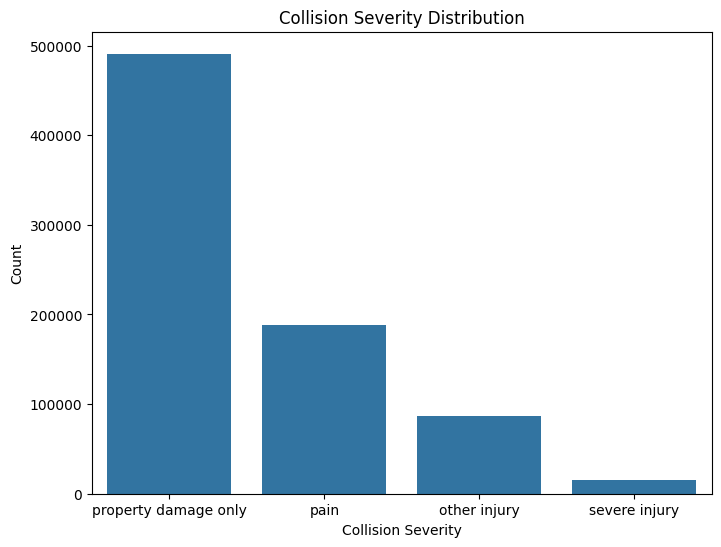

In [38]:
# Univariate Analysis

# Collision Severity Distribution

import matplotlib.pyplot as plt
import seaborn as sns

# Convert to Pandas
# Count collisions in each severity category
severity_counts = (
    collisions_clean_df
    .groupBy("collision_severity")
    .count()
    .orderBy("count", ascending=False)
)

# Convert the aggregated results to Pandas
severity_pd = severity_counts.toPandas()

# Plot
plt.figure(figsize=(8, 6))
sns.barplot(x="collision_severity", y="count", data=severity_pd)
plt.title("Collision Severity Distribution")
plt.xlabel("Collision Severity")
plt.ylabel("Count")
plt.show()


##**3.1.3. Weather conditions during collisions.** <font color = red>[5 marks]</font> <br>

Q: Examine weather conditions during collisions.

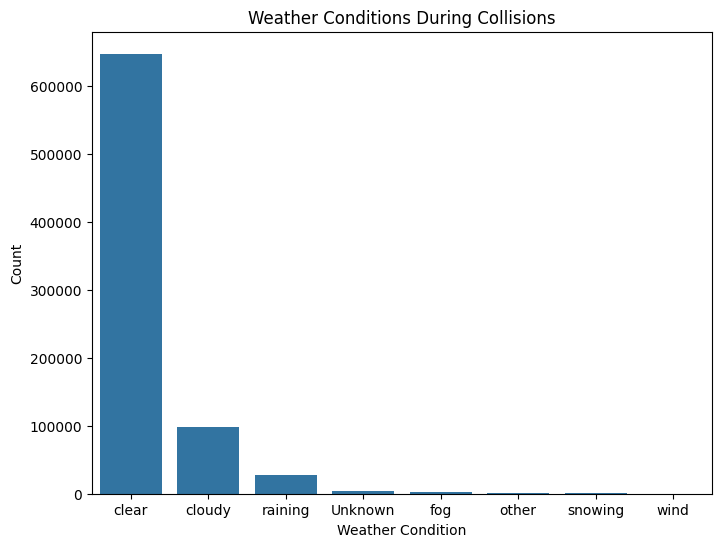

In [39]:
# Weather Conditions During Collisions
weather_counts = (
    collisions_clean_df
    .groupby("weather_1")
    .count()
    .orderBy("count", ascending=False)
)

# Convert to Pandas
weather_counts_pd = weather_counts.toPandas()

# Plot
plt.figure(figsize=(8, 6))
sns.barplot(x="weather_1", y="count", data=weather_counts_pd)
plt.title("Weather Conditions During Collisions")
plt.xlabel("Weather Condition")
plt.ylabel("Count")
plt.show()

##**3.1.4. Victime Age Distribution.** <font color = red>[5 marks]</font> <br>

Q: Analyze the distribution of victim ages.

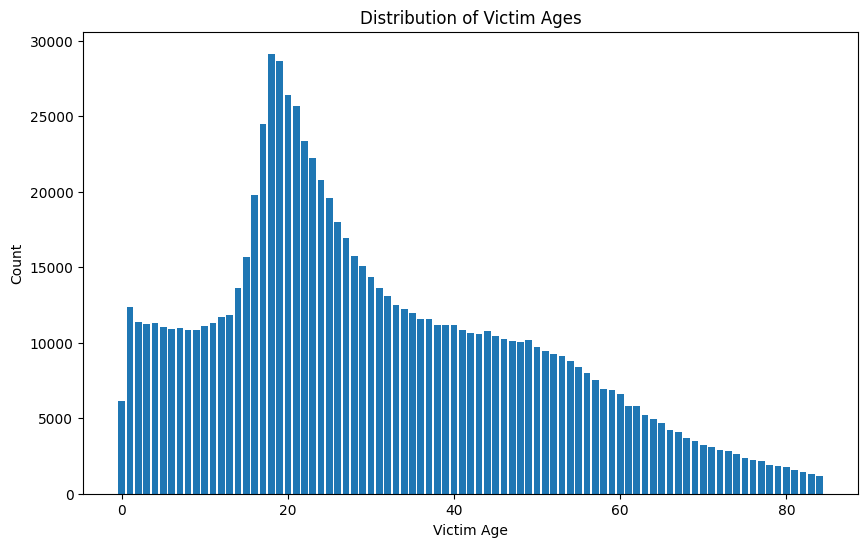

In [40]:
# Distribution of Victim Ages
victims_age_count = (
    victims_clean_df
        .groupby("victim_age")
        .count()
        .orderBy("count", ascending=False)
)

# Convert to Pandas
victims_age_count_pd = victims_age_count.toPandas()

# Plot
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
plt.bar(victims_age_count_pd['victim_age'], victims_age_count_pd['count'])
plt.xlabel('Victim Age')
plt.ylabel('Count')
plt.title('Distribution of Victim Ages')
plt.show()


##**3.1.5. Collision Severity vs Number of Victims.** <font color = red>[5 marks]</font> <br>

Q: Study the relationship between collision severity and the number of victims.

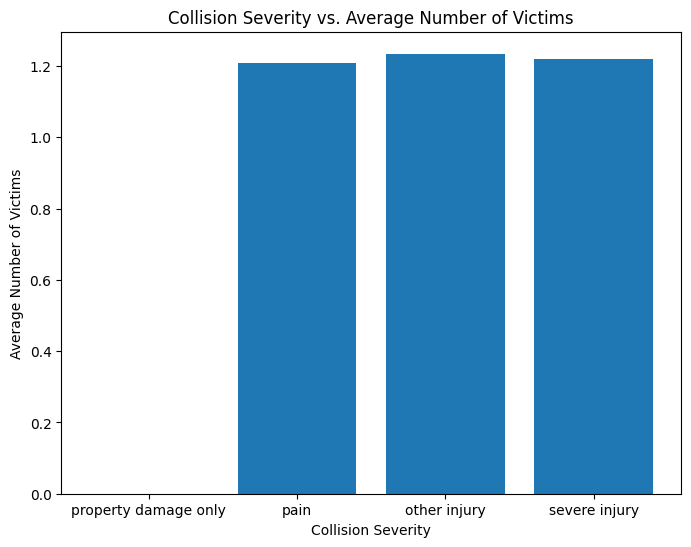

In [41]:
# Bivariate Analysis

# Collision Severity vs. Number of Victims
severity_victims_pd = (
    collisions_clean_df
    .groupBy("collision_severity")
    .agg(
        F.avg(
            F.col("killed_victims") + F.col("injured_victims")
        ).alias("avg_victims")
    )
)

# Convert to Pandas
severity_victims_pd = severity_victims_pd.toPandas()

# Plot
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.bar(severity_victims_pd["collision_severity"], severity_victims_pd["avg_victims"])
plt.xlabel("Collision Severity")
plt.ylabel("Average Number of Victims")
plt.title("Collision Severity vs. Average Number of Victims")
plt.show()


##**3.1.6. Weather Conditions vs Collision Severity.** <font color = red>[5 marks]</font> <br>

Q: Analyze the correlation between weather conditions and collision severity.

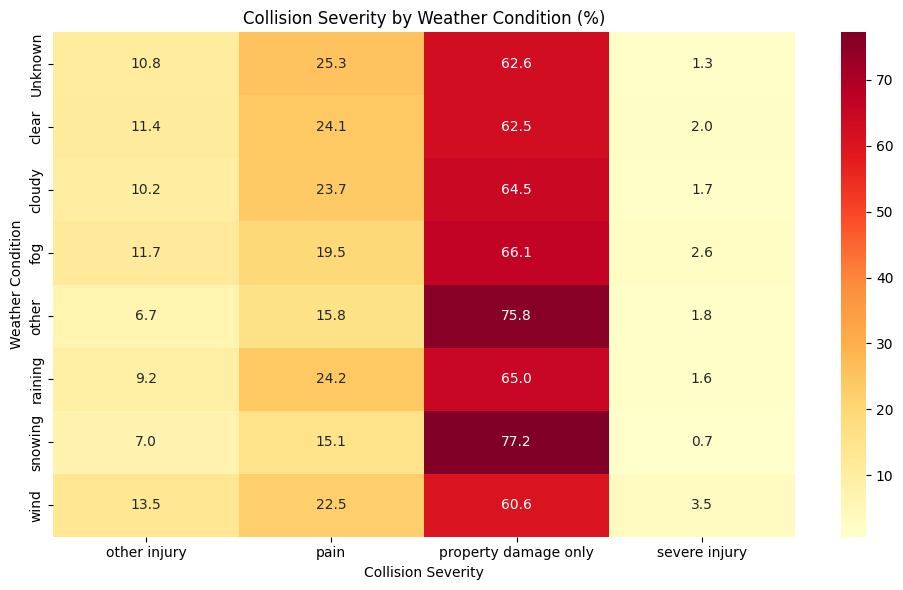

In [42]:
# Weather vs. Collision Severity

# Convert to Pandas
counts = collisions_clean_df.groupBy("weather_1", "collision_severity").count().toPandas()
table = counts.pivot(index="weather_1", columns="collision_severity", values="count").fillna(0)
percentages = table.div(table.sum(axis=1), axis=0) * 100

# Plot
plt.figure(figsize=(10, 6))
sns.heatmap(percentages, annot=True, fmt=".1f", cmap="YlOrRd")
plt.title("Collision Severity by Weather Condition (%)")
plt.xlabel("Collision Severity")
plt.ylabel("Weather Condition")
plt.tight_layout()
plt.show()


##**3.1.7. Lighting conditions vs Collision Severity.** <font color = red>[5 marks]</font> <br>

Q:Visualize the impact of lighting conditions on collision severity.

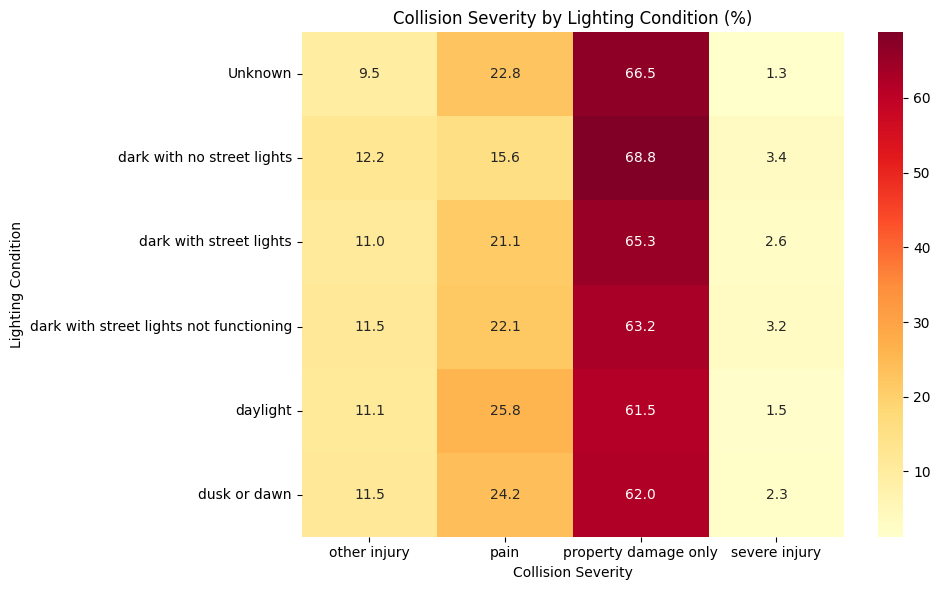

In [48]:
# Lighting Conditions vs. Collision Severity
counts = collisions_clean_df.groupBy("lighting", "collision_severity").count().toPandas()

# Convert to Pandas
table = counts.pivot(index="lighting", columns="collision_severity", values="count").fillna(0)
percentages = table.div(table.sum(axis=1), axis=0) * 100

# Plot
plt.figure(figsize=(10, 6))
sns.heatmap(percentages, annot=True, fmt=".1f", cmap="YlOrRd")
plt.title("Collision Severity by Lighting Condition (%)")
plt.xlabel("Collision Severity")
plt.ylabel("Lighting Condition")
plt.tight_layout()
plt.show()


##**3.1.8. Weekday-Wise Collision Trends.** <font color = red>[7 marks]</font> <br>

Q: Extract and analyze weekday-wise collision trends.

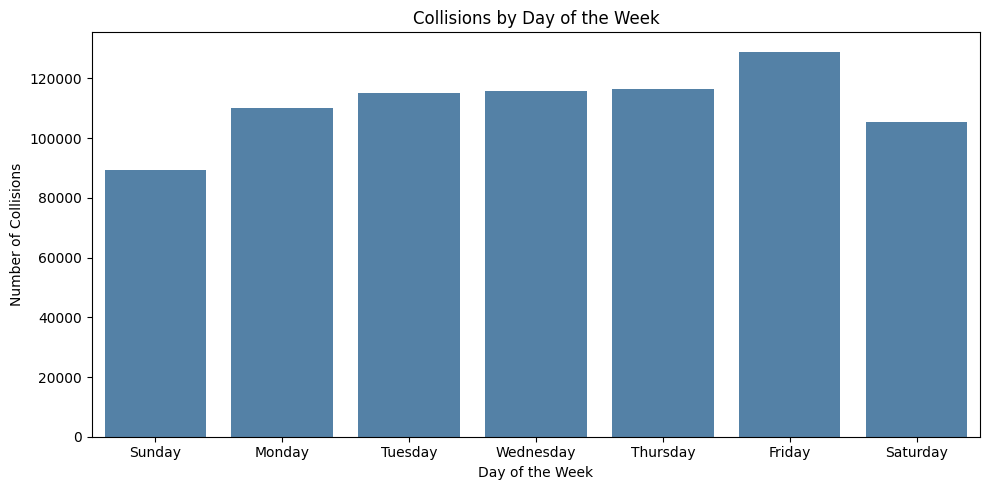

In [49]:
# Extract the weekday
# Extract weekday number and name from the collision date
weekday_counts = (
    collisions_clean_df
    .withColumn("date", F.to_date(F.col("collision_date")))
    .withColumn("weekday_num", F.dayofweek("date"))
    .withColumn("weekday", F.date_format("date", "EEEE"))
    .groupBy("weekday_num", "weekday")
    .count()
    .orderBy("weekday_num")  # Spark: Sunday=1, Monday=2, ..., Saturday=7
    .toPandas()
)

# Plot
plt.figure(figsize=(10, 5))
sns.barplot(data=weekday_counts, x="weekday", y="count", color="steelblue")

plt.title("Collisions by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Number of Collisions")
plt.tight_layout()
plt.show()

In [52]:
collisions_clean_df.describe()

DataFrame[summary: string, case_id: string, jurisdiction: string, officer_id: string, reporting_district: string, chp_shift: string, population: string, county_city_location: string, county_location: string, county_location_index: string, special_condition: string, beat_type: string, chp_beat_type: string, chp_beat_class: string, beat_number: string, primary_road: string, secondary_road: string, distance: string, direction: string, intersection: string, weather_1: string, weather_1_index: string, state_highway_indicator: string, caltrans_county: string, caltrans_district: string, state_route: string, postmile: string, location_type: string, side_of_highway: string, tow_away: string, collision_severity: string, collision_severity_index: string, killed_victims: string, injured_victims: string, party_count: string, primary_collision_factor: string, pcf_violation_category: string, pcf_violation: string, pcf_violation_subsection: string, hit_and_run: string, type_of_collision: string, type_

##**3.1.9. Spatial Distribution of Collisions.** <font color = red>[7 marks]</font> <br>

Q: Study spatial distribution of collisions by county.

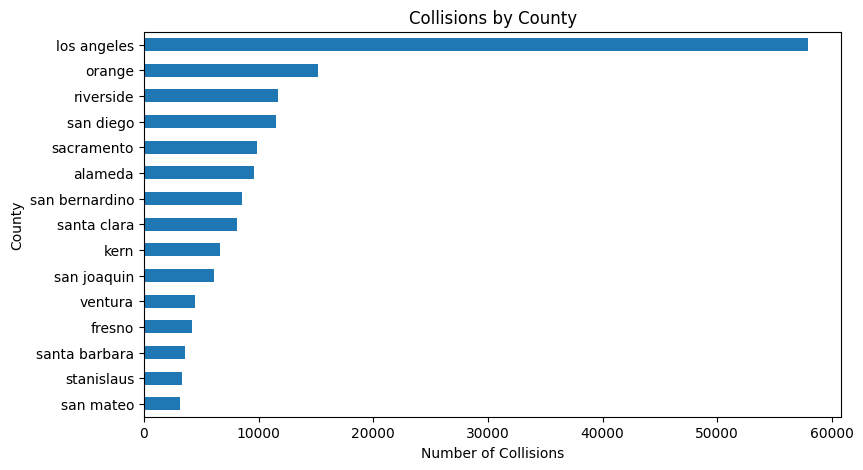

In [57]:
# Spatial Analysis
df = collisions_clean_df.select(
    "county_location", "latitude", "longitude"
).toPandas()

df["latitude"] = pd.to_numeric(df["latitude"], errors="coerce")
df["longitude"] = pd.to_numeric(df["longitude"], errors="coerce")
df = df.dropna(subset=["county_location", "latitude", "longitude"])

# Collision Density by County
county_counts = df["county_location"].value_counts().head(15)

plt.figure(figsize=(9, 5))
county_counts.sort_values().plot(kind="barh")
plt.xlabel("Number of Collisions")
plt.ylabel("County")
plt.title("Collisions by County")
plt.show()

##**3.1.10. Collision Analysis by Geography.** <font color = red>[6 marks]</font> <br>

Q: Generate a scatter plot to analyze collision locations geographically.

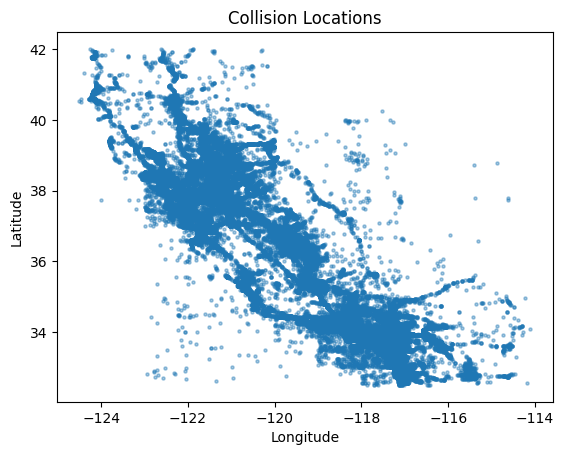

In [54]:
locations = (
    collisions_clean_df
    .select("latitude", "longitude")
    .dropna()
    .toPandas()
)

# Convert to numeric (if needed) and handle invalid data
locations["latitude"] = pd.to_numeric(locations["latitude"], errors="coerce")
locations["longitude"] = pd.to_numeric(locations["longitude"], errors="coerce")
locations = locations.dropna()

# Plot the scatter plot
plt.scatter(locations["longitude"], locations["latitude"], s=5, alpha=0.4)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Collision Locations")
plt.show()

##**3.1.11. Collision Trends Over Time.** <font color = red>[10 marks]</font> <br>

Extract and analyzing collision trends over time.

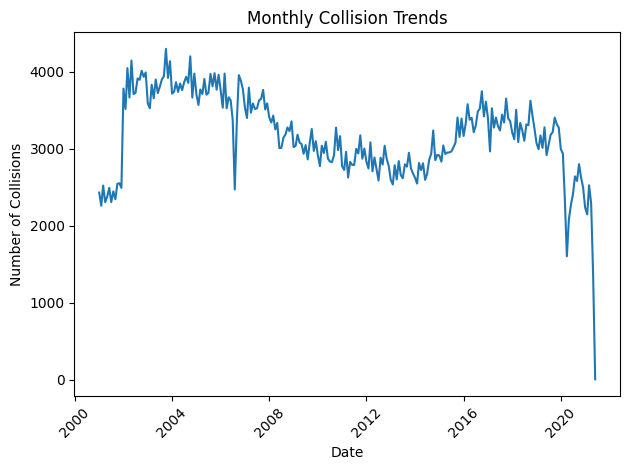

In [58]:
from pyspark.sql.functions import year, month, hour, to_timestamp, col
import pandas as pd
import matplotlib.pyplot as plt

# Extract year and month from collision_date
monthly_counts = (
    collisions_clean_df
    .withColumn("timestamp", to_timestamp(col("collision_date")))
    .withColumn("year", year(col("timestamp")))
    .withColumn("month", month(col("timestamp")))
    .groupBy("year", "month")
    .count()
    .orderBy("year", "month")
    .toPandas()
)

# Plot
monthly_counts["date"] = pd.to_datetime(
    dict(year=monthly_counts.year, month=monthly_counts.month, day=1)
)

plt.plot(monthly_counts["date"], monthly_counts["count"])
plt.xlabel("Date")
plt.ylabel("Number of Collisions")
plt.title("Monthly Collision Trends")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Q: Analyze yearly, monthly and hourly trends in collisions.

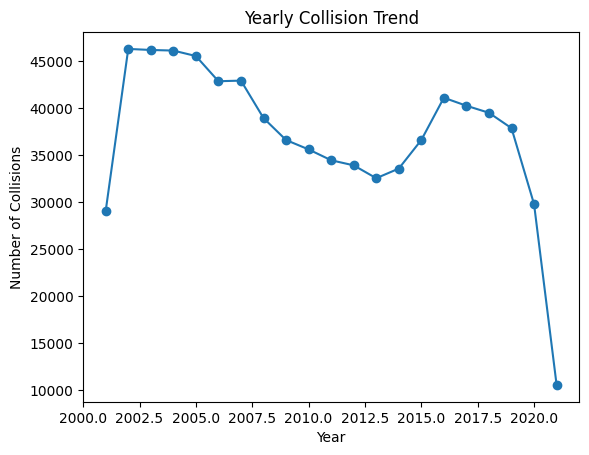

In [59]:
# Yearly Trend of Collisions
# Extract year, month, and hour
trends = (
    collisions_clean_df
    .withColumn("timestamp", to_timestamp(col("collision_date")))
    .filter(col("timestamp").isNotNull())
    .withColumn("year", year(col("timestamp")))
    .withColumn("month", month(col("timestamp")))
    .withColumn("hour", hour(col("timestamp")))
)

# Yearly Trend of Collisions
yearly = trends.groupBy("year").count().orderBy("year").toPandas()


# Plot
plt.plot(yearly["year"], yearly["count"], marker="o")
plt.title("Yearly Collision Trend")
plt.xlabel("Year")
plt.ylabel("Number of Collisions")
plt.show()

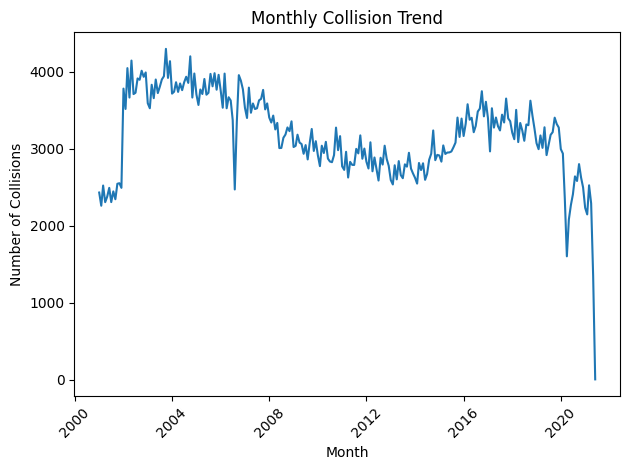

In [60]:
# Monthly Trend of Collisions
monthly = trends.groupBy("year", "month").count().orderBy("year", "month").toPandas()
monthly["date"] = pd.to_datetime(
    dict(year=monthly.year, month=monthly.month, day=1)
)

# Plot
plt.plot(monthly["date"], monthly["count"])
plt.title("Monthly Collision Trend")
plt.xlabel("Month")
plt.ylabel("Number of Collisions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

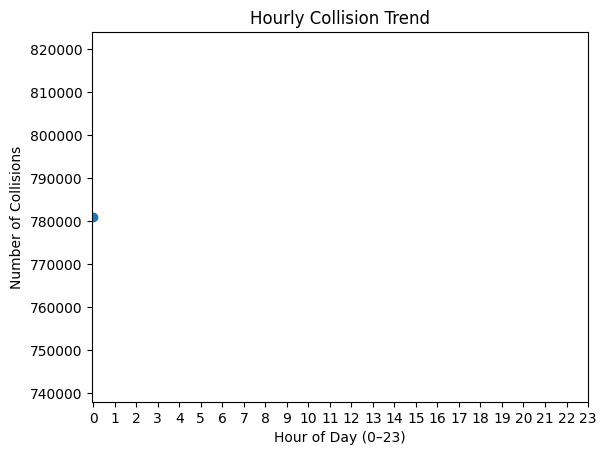

In [61]:
# Hourly Trend of Collisions
hourly = trends.groupBy("hour").count().orderBy("hour").toPandas()

# Plot
plt.plot(hourly["hour"], hourly["count"], marker="o")
plt.title("Hourly Collision Trend")
plt.xlabel("Hour of Day (0–23)")
plt.ylabel("Number of Collisions")
plt.xticks(range(24))
plt.show()

#**4. ETL Querying** <font color = red>[35 marks]</font> <br>

## **4.1. Top 5 Counties** <font color = red>[4 marks]</font> <br>

Q: Identify the top 5 counties with the highest number of collisions.

In [64]:
from pyspark.sql.functions import col, desc
# Query: Identify the top 5 counties with the most collisions
collisions_clean_df \
    .filter(col("county_location").isNotNull()) \
    .groupBy("county_location") \
    .count() \
    .orderBy(desc("count")) \
    .limit(5) \
    .show()


+---------------+------+
|county_location| count|
+---------------+------+
|    los angeles|253556|
|         orange| 62734|
| san bernardino| 44830|
|      san diego| 41756|
|        alameda| 39057|
+---------------+------+



## **4.2. Month with Highest Collisions** <font color = red>[5 marks]</font> <br>

Q. Identify the month with the highest number of collisions.

In [65]:
# Query: Find the month with the highest number of collisions
from pyspark.sql.functions import month, to_timestamp, col, desc

collisions_clean_df \
    .withColumn("month", month(to_timestamp(col("collision_date")))) \
    .filter(col("month").isNotNull()) \
    .groupBy("month") \
    .count() \
    .orderBy(desc("count")) \
    .limit(1) \
    .show()

+-----+-----+
|month|count|
+-----+-----+
|   10|69599|
+-----+-----+



## **4.3. Weather Conditions with Highest Collisions.** <font color = red>[5 marks]</font> <br>

Q. Determine the most common weather condition during collisions.

In [66]:
# Query: Find the most common weather condition during collisions
from pyspark.sql.functions import col, desc

collisions_clean_df \
    .filter(col("weather_1").isNotNull()) \
    .groupBy("weather_1") \
    .count() \
    .orderBy(desc("count")) \
    .limit(1) \
    .show()

+---------+------+
|weather_1| count|
+---------+------+
|    clear|647360|
+---------+------+



## **4.4. Fatal Collisions.** <font color = red>[5 marks]</font> <br>

Q. Calculate the percentage of collisions that resulted in fatalities.

In [67]:
# Query: Determine the percentage of collisions that resulted in fatalities
from pyspark.sql.functions import col, when, count, sum as spark_sum, round

result = (
    collisions_clean_df
    .withColumn("killed", col("killed_victims").cast("int"))
    .agg(
        count("*").alias("total_collisions"),
        spark_sum(when(col("killed") > 0, 1).otherwise(0))
            .alias("fatal_collisions")
    )
    .withColumn(
        "fatal_collision_percentage",
        round(col("fatal_collisions") / col("total_collisions") * 100, 2)
    )
)

result.show()

+----------------+----------------+--------------------------+
|total_collisions|fatal_collisions|fatal_collision_percentage|
+----------------+----------------+--------------------------+
|          780981|               0|                       0.0|
+----------------+----------------+--------------------------+



## **4.5. Dangerous Time for Collisions.** <font color = red>[5 marks]</font> <br>

Q. Find the most dangerous time of day for collisions.

In [68]:
# Query: Find the most dangerous time of day for collisions
from pyspark.sql.functions import hour, to_timestamp, col, desc

collisions_clean_df \
    .withColumn("hour", hour(to_timestamp(col("collision_date")))) \
    .filter(col("hour").isNotNull()) \
    .groupBy("hour") \
    .count() \
    .orderBy(desc("count")) \
    .limit(1) \
    .show()


+----+------+
|hour| count|
+----+------+
|   0|780981|
+----+------+



## **4.6. Road Surface Conditions.** <font color = red>[5 marks]</font> <br>

Q. Identify the top 5 road surface conditions with the highest collision frequency.

In [69]:
# Query: List the top 5 road types with the highest collision frequency
from pyspark.sql.functions import col, desc

collisions_clean_df \
    .filter(col("chp_road_type").isNotNull()) \
    .groupBy("chp_road_type") \
    .count() \
    .orderBy(desc("count")) \
    .limit(5) \
    .show()

+-------------+------+
|chp_road_type| count|
+-------------+------+
|          0.0|658173|
|          1.0|111210|
|          6.0|  8613|
|          5.0|  1825|
|          4.0|   857|
+-------------+------+



## **4.7. Lighting Conditions.** <font color = red>[5 marks]</font> <br>

Q. Analyze lighting conditions that contribute to the highest number of collisions.

In [70]:
# Query: Find the top 3 lighting conditions that lead to the most collisions
from pyspark.sql.functions import col, desc

collisions_clean_df \
    .filter(col("lighting").isNotNull()) \
    .groupBy("lighting") \
    .count() \
    .orderBy(desc("count")) \
    .limit(3) \
    .show()

+--------------------+------+
|            lighting| count|
+--------------------+------+
|            daylight|523519|
|dark with street ...|177306|
|dark with no stre...| 46904|
+--------------------+------+



#5. Conclusion <font color = red>[10 marks]</font> <br>

Write your conclusion.

In [ ]:
# Final insights
1. Los angeles has highest number of collisions
2. Collision peaked in October month
3. In clear weather conditions, collisions are most frequent
4. Most collisions occured in daylight.
5. Most collisions happened in 0th hour.

#Recommendations
1. Review collision hotspots in Los Angeles County and compare them with traffic volume before setting priorities.
2. Check why on clear day most accidents are happening. Do we need to impose speed limits.
3. Investigate why most collisions happen during the 0th hour and consider implementing measures to improve safety during this time.
4. Analyze the reasons behind the peak in collisions during October and take preventive actions accordingly.
5. Investigate why most collisions occur in daylight and consider measures to enhance safety during these hours.

#6. Visualization Integration using Tableau/ PowerBI <font color = red>[Optional]</font> <br>